# Lo scenario e i dati

**Azienda:** ToysGroup distribuisce giocattoli tramite una rete di rivenditori in diverse aree geografiche. I dati del Modulo 3 sono esportati in quattro file di formato diverso, forniti dal docente, da leggere, pulire, analizzare e modellare in Python.

### Anagrafiche · CSV ed Excel
- `products.csv`: ProductID, ProductName, Category, ListPrice.
- `regions.xlsx`: RegionID, State, SalesRegion (lo stato appartiene a una regione di vendita).

**Chiavi: ProductID e RegionID.**

### Vendite · JSON
- `sales.json`: SalesID, ProductID, RegionID, ResellerID, SalesDate, Quantity, SalesAmount.
- Una riga per transazione, con valori mancanti in Quantity e SalesAmount.

**Fatti di vendita collegati alle anagrafiche.**

### Rivenditori · CSV
- `resellers.csv`: ResellerID, RegionID, Ordini12m, GiorniUltimoOrdine, ScontoMedio, Reclami.
- Churn = 1 se il rivenditore non riordina da oltre 6 mesi.

**Base per classificazione e clustering.**

---

> **Consegna finale (entro 2 giornate lavorative):** un unico notebook .ipynb eseguibile dall'inizio senza errori, con le celle nell'ordine dei task; ogni cella di codice è preceduta da una cella Markdown con il numero del task e la risposta richiesta. Notebook e dati vanno su GitHub (Task 7).

## Costrutti disponibili

| Concetto | Definizione | Esempio |
|---|---|---|
| List comprehension | costruisce una nuova lista applicando un'espressione a ogni elemento di un iterabile, con un filtro if opzionale | `[p["ListPrice"] for p in products if p["Category"] == "Bikes"]` |
| `.loc[]` e `.iloc[]` | `.loc[]` seleziona righe e colonne per etichetta o maschera booleana; `.iloc[]` per posizione intera | `df.loc[df["ListPrice"] > 30, "ProductName"]`; `df.iloc[10:20, :3]` |
| `groupby()` e `agg()` | divide il DataFrame in gruppi per valore della chiave e applica a ciascun gruppo una o più funzioni di aggregazione | `df.groupby("Category").agg(Fatturato=("SalesAmount", "sum"))` |
| `merge()` e `concat()` | `merge()` affianca le colonne di due DataFrame in base a una chiave comune; `concat()` accoda righe o colonne | `pd.merge(sales, products, on="ProductID", how="left")` |
| Workflow Scikit-learn | sequenza comune a ogni estimator: split dei dati, creazione del modello, fit() sul training, predict() e valutazione sul test | `model = LinearRegression().fit(X_train, y_train)`; `model.score(X_test, y_test)` |

# Task 1 · Python di base sui dati forniti
*Python for Data Science · Parti 1 e 2 · Giorno 1 · circa 1,5 ore*

**Consegna:** sui quattro file forniti dal docente, svolgere i primi calcoli con strutture dati, cicli e funzioni Python, senza metodi di analisi Pandas.

1. leggere `products.csv` e `sales.json` e convertirli con `.to_dict(orient="records")` in liste di dizionari; costruire `regions` come dizionario `{RegionID: (State, SalesRegion)}` e il set delle categorie.
2. con una list comprehension e un costrutto `if/elif/else` assegnare a ogni prodotto la fascia di prezzo: Bassa sotto 20 €, Media fino a 60 €, Alta oltre.
3. scrivere la funzione `fatturato_categoria(vendite, prodotti, categoria)` che con un ciclo `for` somma `SalesAmount` della categoria, salta i valori mancanti e restituisce il totale con `return`.
4. con un ciclo `while` contare le transazioni necessarie a superare 10.000 € di fatturato cumulato; mostrare le prime cinque transazioni con `vendite[:5]`.

**Vincolo:** Pandas si usa solo per leggere i file e convertirli; somme, conteggi e classificazioni si calcolano con costrutti Python.

**Definizione richiesta:** differenza tra lista, tupla, set e dizionario per mutabilità, ordine, duplicati e modalità di accesso (indice o chiave).

> **Criterio di completamento:** `len()` di lista prodotti, dizionario regions e set delle categorie riportata; fascia assegnata a ogni prodotto; fatturato per categoria da `fatturato_categoria()`, da confrontare con il Task 3b.

In [1]:
# Es 1 Punto 1

import pandas as pd

# dataframe
products_df = pd.read_csv("data/products.csv")
sales_df = pd.read_json("data/sales.json")
regions_df = pd.read_excel("data/regions.xlsx")
resellers_df = pd.read_csv("data/resellers.csv")

# liste di dizionari
products = products_df.to_dict(orient="records")
sales = sales_df.to_dict(orient="records")

# dizionario regions
regions = {
    r["RegionID"]: (r["State"], r["SalesRegion"])
    for r in regions_df.to_dict(orient="records")
}

# Set delle categorie
categories = {p["Category"] for p in products}

print("Products:", len(products))
print("Sales:", len(sales))
print("Regions:", len(regions))
print("Categories:", len(categories), categories)

Products: 12
Sales: 2000
Regions: 9
Categories: 3 {'Giocattoli', 'Giochi da tavolo', 'Outdoor'}


In [2]:
# Es 1 punto 2

def price_band(price):
    if price < 20:
        return "Bassa"
    elif price <= 60:
        return "Media"
    else:
        return "Alta"

bands = [price_band(p["ListPrice"]) for p in products]

# nuova lista di dizionari con la fascia di prezzo, senza modificare products

products_banded = [{**p, "PriceBand": price_band(p["ListPrice"])} for p in products]

# verifiche
print([p for p in products if p["ListPrice"] != p["ListPrice"]])
products_banded[:5]


[]


[{'ProductID': 1,
  'ProductName': 'Bici Junior',
  'Category': 'Outdoor',
  'ListPrice': 129.0,
  'PriceBand': 'Alta'},
 {'ProductID': 2,
  'ProductName': 'Bici BMX',
  'Category': 'Outdoor',
  'ListPrice': 189.0,
  'PriceBand': 'Alta'},
 {'ProductID': 3,
  'ProductName': 'Monopattino',
  'Category': 'Outdoor',
  'ListPrice': 79.0,
  'PriceBand': 'Alta'},
 {'ProductID': 4,
  'ProductName': 'Pallone Calcio',
  'Category': 'Outdoor',
  'ListPrice': 19.9,
  'PriceBand': 'Bassa'},
 {'ProductID': 5,
  'ProductName': 'Racchette Beach',
  'Category': 'Outdoor',
  'ListPrice': 14.5,
  'PriceBand': 'Bassa'}]

In [3]:
# Es 1 punto 3

def fatturato_categoria(sales, products, category):
    # 1. set dei ProductID che appartengono alla categoria
    product_ids = {p["ProductID"] for p in products if p["Category"] == category}

    # 2. totale iniziale
    total = 0

    # 3. ciclo for sulle vendite
    for s in sales:
        amount = s["SalesAmount"]
        if amount != amount:                 # nan: valore mancante, si salta
            continue
        if s["ProductID"] in product_ids:    # vendita della categoria richiesta
            total += amount

    # 4. restituzione del totale
    return total


# fatturato per ogni categoria
for c in categories:
    print(c, round(fatturato_categoria(sales, products, c), 2))

Giocattoli 174832.0
Giochi da tavolo 53245.1
Outdoor 331998.4


### Task 1 · Punto 3
Funzione `fatturato_categoria()`: con un ciclo `for` somma `SalesAmount` delle vendite della categoria, saltando i valori mancanti, e restituisce il totale con `return`.

Fatturato per categoria:
- Giochi da tavolo: 53.245,10 €
- Giocattoli: 174.832,00 €
- Outdoor: 331.998,40 €

In [4]:
# Es 1 punto 4

total = 0
count = 0

while total <= 10000 and count < len(sales):
    amount = sales[count]["SalesAmount"]
    if amount == amount:          # salta i nan
        total += amount
    count += 1

print("Transazioni necessarie:", count)
print("Fatturato cumulato:", round(total, 2))

# prime cinque transazioni
sales[:5]

Transazioni necessarie: 56
Fatturato cumulato: 10164.8


[{'SalesID': 1194,
  'ProductID': 6,
  'RegionID': 7,
  'ResellerID': 283,
  'SalesDate': '2023-01-01',
  'Quantity': 4.0,
  'SalesAmount': 71.6},
 {'SalesID': 859,
  'ProductID': 6,
  'RegionID': 8,
  'ResellerID': 28,
  'SalesDate': '2023-01-02',
  'Quantity': 7.0,
  'SalesAmount': nan},
 {'SalesID': 1747,
  'ProductID': 12,
  'RegionID': 3,
  'ResellerID': 281,
  'SalesDate': '2023-01-02',
  'Quantity': 2.0,
  'SalesAmount': 118.0},
 {'SalesID': 279,
  'ProductID': 3,
  'RegionID': 7,
  'ResellerID': 128,
  'SalesDate': '2023-01-02',
  'Quantity': 3.0,
  'SalesAmount': nan},
 {'SalesID': 1470,
  'ProductID': 1,
  'RegionID': 6,
  'ResellerID': 137,
  'SalesDate': '2023-01-04',
  'Quantity': 4.0,
  'SalesAmount': nan}]

### Task 1 · Definizione richiesta
**Differenza tra lista, tupla, set e dizionario**

| Struttura | Sintassi | Mutabile | Ordinata | Duplicati | Accesso |
|---|---|---|---|---|---|
| **Lista** | `[1, 2, 3]` | Sì | Sì | Ammessi | Per indice: `lista[0]` |
| **Tupla** | `(1, 2, 3)` | No | Sì | Ammessi | Per indice: `tupla[0]` |
| **Set** | `{1, 2, 3}` | Sì | No | Non ammessi | Nessun indice: solo appartenenza (`x in set`) o iterazione |
| **Dizionario** | `{"a": 1}` | Sì | Sì, ordine di inserimento (da Python 3.7) | Chiavi uniche, valori ripetibili | Per chiave: `diz["a"]` |

- **Mutabilità:** lista, set e dizionario si possono modificare dopo la creazione (aggiungere, togliere, cambiare elementi); la tupla no, una volta creata resta fissa.
- **Ordine:** lista e tupla mantengono la posizione degli elementi; il dizionario mantiene l'ordine di inserimento delle chiavi; il set non garantisce alcun ordine.
- **Duplicati:** il set li elimina automaticamente; nel dizionario le chiavi sono uniche.
- **Accesso:** lista e tupla per indice numerico, dizionario per chiave, set solo verificando se un elemento è presente.

**Nel Task 1:**
- `products` e `sales` sono **liste** di dizionari: sequenze ordinate di record da scorrere con un ciclo.
- Ogni singolo prodotto o vendita è un **dizionario**: si accede ai campi per chiave (`p["ListPrice"]`).
- `regions` è un **dizionario** `{RegionID: (State, SalesRegion)}`: tabella di consultazione con accesso diretto per chiave.
- La coppia `(State, SalesRegion)` è una **tupla**: due valori fissi che non devono cambiare.
- `categories` è un **set**: raccoglie le categorie una sola volta, eliminando i duplicati.

# Task 2 · Lettura e ispezione dei dati
*Pandas & NumPy · Parte 1 · Giorno 1 · circa 1 ora*

**Consegna:** leggere i quattro file in DataFrame e descriverne struttura e contenuto prima di qualsiasi modifica.

1. leggere i file con `pd.read_csv()`, `pd.read_excel()` e `pd.read_json()` e riportare per ciascuno `.shape`, `.info()`, `.head()` e `.tail()`.
2. con `.describe()` individuare minimo, massimo e media di Quantity e SalesAmount; convertire le due colonne in array NumPy e calcolare con un'operazione vettoriale il prezzo unitario di ogni vendita.
3. selezionare con `.loc[]` e una maschera booleana i prodotti di una categoria con ListPrice superiore a 30 €; con `.iloc[]` le righe da 10 a 19 e le prime tre colonne di sales.

**Definizione richiesta:** differenza tra Series e DataFrame e tra `.loc[]` (selezione per etichetta) e `.iloc[]` (selezione per posizione).

**Vincolo:** nessuna modifica ai DataFrame in questo task: solo lettura, descrizione e selezione.

> **Criterio di completamento:** per ogni DataFrame sono riportati righe, colonne, tipi e conteggio dei non nulli; la selezione con `.iloc[]` restituisce 10 righe e 3 colonne.

In [5]:
# Es 2 punto 1

dataframes = {
    "products": products_df,
    "sales": sales_df,
    "regions": regions_df,
    "resellers": resellers_df,
}

for name, df in dataframes.items():
    print(f"===== {name} =====")
    print("Shape:", df.shape)
    df.info()
    display(df.head())
    display(df.tail())

===== products =====
Shape: (12, 4)
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     str    
 2   Category     12 non-null     str    
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 516.0 bytes


,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0
3,4,Pallone Calcio,Outdoor,19.9
4,5,Racchette Beach,Outdoor,14.5


,ProductID,ProductName,Category,ListPrice
7,8,Scacchi Legno,Giochi da tavolo,34.0
8,9,Costruzioni 500,Giocattoli,39.9
9,10,Bambola Classica,Giocattoli,24.9
10,11,Robot RC,Giocattoli,89.0
11,12,Macchinina RC,Giocattoli,59.0


===== sales =====
Shape: (2000, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SalesID      2000 non-null   int64  
 1   ProductID    2000 non-null   int64  
 2   RegionID     2000 non-null   int64  
 3   ResellerID   2000 non-null   int64  
 4   SalesDate    2000 non-null   str    
 5   Quantity     1900 non-null   float64
 6   SalesAmount  1900 non-null   float64
dtypes: float64(2), int64(4), str(1)
memory usage: 109.5 KB


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
0,1194,6,7,283,2023-01-01,4.0,71.6
1,859,6,8,28,2023-01-02,7.0,NaN
2,1747,12,3,281,2023-01-02,2.0,118.0
3,279,3,7,128,2023-01-02,3.0,NaN
4,1470,1,6,137,2023-01-04,4.0,NaN


...

,RegionID,State,SalesRegion
0,1,Italia,Sud Europa
1,2,Francia,Sud Europa
2,3,Spagna,Sud Europa
3,4,Germania,Centro Europa
4,5,Austria,Centro Europa


,RegionID,State,SalesRegion
4,5,Austria,Centro Europa
5,6,Svizzera,Centro Europa
6,7,Svezia,Nord Europa
7,8,Norvegia,Nord Europa
8,9,Danimarca,Nord Europa


===== resellers =====
Shape: (300, 7)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ResellerID          300 non-null    int64  
 1   RegionID            300 non-null    int64  
 2   Ordini12m           300 non-null    int64  
 3   GiorniUltimoOrdine  300 non-null    int64  
 4   ScontoMedio         300 non-null    float64
 5   Reclami             300 non-null    int64  
 6   Churn               300 non-null    int64  
dtypes: float64(1), int64(6)
memory usage: 16.5 KB


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
0,1,1,14,65,0.131,1,0
1,2,7,9,149,0.117,1,0
2,3,6,21,1,0.065,2,0
3,4,4,18,162,0.011,1,1
4,5,4,22,98,0.120,0,0


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
295,296,5,18,145,0.218,1,0
296,297,8,17,104,0.048,0,0
297,298,4,16,141,0.055,2,0
298,299,3,13,113,0.164,0,0
299,300,1,12,116,0.072,0,0


### Task 2 · Punto 1
Lettura dei quattro file in DataFrame e ispezione con `.shape`, `.info()`, `.head()` e `.tail()`.

| DataFrame | Righe | Colonne | Valori mancanti |
|---|---|---|---|
| products | 12 | 4 | nessuno |
| sales | 2000 | 7 | Quantity e SalesAmount: 100 ciascuna (1900 non nulli) |
| regions | 9 | 3 | nessuno |
| resellers | 300 | 7 | nessuno |

**Tipi delle colonne**
- **products:** ProductID `int64`; ProductName, Category `str`; ListPrice `float64`.
- **sales:** SalesID, ProductID, RegionID, ResellerID `int64`; SalesDate `str`; Quantity, SalesAmount `float64`.
- **regions:** RegionID `int64`; State, SalesRegion `str`.
- **resellers:** ResellerID, RegionID, Ordini12m, GiorniUltimoOrdine, Reclami, Churn `int64`; ScontoMedio `float64`.

**Osservazioni**
- Gli unici valori mancanti sono in `sales`, nelle colonne Quantity e SalesAmount.
- Quantity è `float64` anche se rappresenta quantità intere: dipende dalla presenza dei valori mancanti (NaN è un float).
- SalesDate è letta come testo, non come data: andrà convertita nella fase di pulizia.
- Churn in resellers è già codificato come intero 0/1, pronto per la classificazione.
- Le colonne di testo risultano `str`.

In [6]:
# Es 2 punto 2

# import numpy:

import numpy as np

# statistiche descrittive di Quantity e SalesAmount
display(sales_df[["Quantity", "SalesAmount"]].describe())

# conversione delle due colonne in array NumPy
quantity = sales_df["Quantity"].to_numpy()
amount = sales_df["SalesAmount"].to_numpy()

# prezzo unitario con un'operazione vettoriale
unit_price = amount / quantity

print("Prime 10 vendite, prezzo unitario:", unit_price[:10])
print("Valori calcolati:", np.count_nonzero(~np.isnan(unit_price)), "su", len(unit_price))
print("Prezzo unitario medio:", round(np.nanmean(unit_price), 2))

,Quantity,SalesAmount
count,1900.000000,1900.000000
mean,4.966316,294.776579
std,2.206535,305.261212
min,1.000000,12.500000
25%,3.000000,89.000000
50%,5.000000,177.000000
75%,6.000000,387.000000
max,14.000000,2457.000000


Prime 10 vendite, prezzo unitario: [17.9  nan 59.   nan  nan 12.5 79.  79.  12.5  nan]
Valori calcolati: 1802 su 2000
Prezzo unitario medio: 58.8


### Task 2 · Punto 2
Statistiche descrittive con `.describe()` e calcolo vettoriale del prezzo unitario con NumPy.

| | Quantity | SalesAmount |
|---|---|---|
| Valori non nulli | 1900 | 1900 |
| Minimo | 1 | 12,50 € |
| Massimo | 14 | 2.457,00 € |
| Media | 4,97 | 294,78 € |
| Mediana | 5 | 177,00 € |

**Prezzo unitario** (`SalesAmount / Quantity`, operazione vettoriale tra array NumPy):
- calcolato per 1802 vendite su 2000; le altre 198 hanno almeno un valore mancante e restituiscono `NaN` (2 vendite hanno mancanti entrambe le colonne);
- prezzo unitario medio: 58,80 € (calcolato con `np.nanmean()`, che ignora i `NaN`).

**Osservazioni**
- I prezzi unitari coincidono con i `ListPrice` dei prodotti: `SalesAmount = Quantity × ListPrice`, senza sconti. In fase di pulizia i valori mancanti potranno essere ricostruiti dal listino.
- SalesAmount ha una distribuzione asimmetrica: la media (294,78 €) è molto più alta della mediana (177 €) e la deviazione standard (305 €) supera la media, segno di poche vendite di importo elevato.
- Il massimo di 2.457 € corrisponde a 13 unità × 189 € (Bici BMX), quindi è un valore plausibile e non un errore.
- Quantity va da 1 a 14, con media e mediana intorno a 5.
- Il prezzo unitario è tenuto in un array separato: `sales_df` non viene modificato, come richiesto dal vincolo.

In [7]:
# Es 2 punto 3

# .loc[] con maschera booleana: prodotti Outdoor con ListPrice > 30 €
mask = (products_df["Category"] == "Outdoor") & (products_df["ListPrice"] > 30)
display(products_df.loc[mask])

# .iloc[]: righe da 10 a 19 e prime tre colonne di sales
sales_slice = sales_df.iloc[10:20, :3]
display(sales_slice)
print("Shape:", sales_slice.shape)

,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0


,SalesID,ProductID,RegionID
10,218,1,8
11,1136,1,9
12,1326,3,4
13,1063,9,7
14,1606,10,8
15,1283,12,1
16,98,3,4
17,156,6,8
18,1642,12,5
19,1644,4,7


Shape: (10, 3)


### Task 2 · Definizione richiesta

**Series e DataFrame**

| | Series | DataFrame |
|---|---|---|
| Dimensioni | 1 (una colonna di valori) | 2 (righe e colonne) |
| Struttura | valori + indice | più Series che condividono lo stesso indice |
| Tipo di dato | uno solo per tutta la Series | uno per ogni colonna |
| Esempio nel task | `sales_df["Quantity"]` | `sales_df`, `sales_df[["Quantity", "SalesAmount"]]` |

Una Series è una singola colonna con il suo indice; un DataFrame è una tabella formata da più Series affiancate. Selezionare una colonna con parentesi singole (`df["col"]`) restituisce una Series, con parentesi doppie (`df[["col"]]`) un DataFrame. Anche la maschera booleana usata con `.loc[]` è una Series di `True`/`False`.

**`.loc[]` e `.iloc[]`**

| | `.loc[]` | `.iloc[]` |
|---|---|---|
| Selezione | per **etichetta** (nome di riga/colonna) o maschera booleana | per **posizione** intera (0, 1, 2…) |
| Estremo finale dello slicing | incluso | escluso |
| Colonne | per nome: `["ProductName", "ListPrice"]` | per posizione: `:3` |
| Esempio nel task | `products_df.loc[mask]` | `sales_df.iloc[10:20, :3]` |

In `sales_df` le etichette delle righe coincidono con le posizioni solo perché l'indice è quello di default (0…1999): `.loc[10:19]` e `.iloc[10:20]` restituiscono qui le stesse 10 righe. Con un indice diverso, ad esempio dopo un filtro o usando `SalesID` come indice, darebbero risultati diversi.

# Task 3a · Dati mancanti, filtri e ordinamento
*Pandas & NumPy · Parte 2 · Giorno 1 · circa 1 ora*

**Consegna:** rendere il DataFrame delle vendite pronto per l'analisi, trattando i valori mancanti e isolando i sottoinsiemi richiesti.

1. contare i NaN per colonna con `.isna().sum()` e calcolarne la percentuale sul numero totale di righe.
2. imputare Quantity con la mediana della colonna tramite `fillna()` ed eliminare con `dropna()` le righe con SalesAmount mancante, dichiarando il numero di righe rimosse.
3. con `.query()` estrarre le transazioni con SalesAmount superiore al 90° percentile (`quantile(0.9)`) e ordinarle con `sort_values()` per data crescente e importo decrescente.

**Definizione richiesta:** imputazione dei dati mancanti: cos'è, quando preferire media, mediana o eliminazione della riga e quale effetto ha ciascuna scelta sulla distribuzione.

**Attenzione:** la mediana si calcola sui valori presenti prima del `fillna()`; dopo l'imputazione

In [8]:
# Es 3a punto 1

# copia di lavoro: sales_df resta l'originale
sales_clean = sales_df.copy()

# conteggio dei NaN per colonna e percentuale sul totale delle righe
nan_before = pd.DataFrame({
    "NaN": sales_clean.isna().sum(),
    "Percentuale": (sales_clean.isna().sum() / len(sales_clean) * 100).round(2),
})

nan_before

,NaN,Percentuale
SalesID,0,0.0
ProductID,0,0.0
RegionID,0,0.0
ResellerID,0,0.0
SalesDate,0,0.0
Quantity,100,5.0
SalesAmount,100,5.0


### Task 3a · Punto 1
Conteggio dei valori mancanti per colonna con `.isna().sum()` e percentuale sul totale di 2000 righe, su una copia di lavoro (`sales_clean`) per lasciare intatto `sales_df`.

| Colonna | NaN | % |
|---|---|---|
| SalesID, ProductID, RegionID, ResellerID, SalesDate | 0 | 0,0% |
| Quantity | 100 | 5,0% |
| SalesAmount | 100 | 5,0% |

Le chiavi e la data sono complete; i valori mancanti riguardano solo le due misure di vendita.

In [9]:
# Es 3a punto 2

# mediana di Quantity calcolata sui valori presenti, PRIMA del fillna
quantity_median = sales_clean["Quantity"].median()
print("Mediana di Quantity:", quantity_median)

# imputazione di Quantity con la mediana
sales_clean["Quantity"] = sales_clean["Quantity"].fillna(quantity_median)

# eliminazione delle righe con SalesAmount mancante
rows_before = len(sales_clean)
sales_clean = sales_clean.dropna(subset=["SalesAmount"])
rows_removed = rows_before - len(sales_clean)
print("Righe prima:", rows_before)
print("Righe rimosse:", rows_removed)
print("Righe dopo:", len(sales_clean))

# tabella dei NaN prima e dopo il trattamento
nan_after = sales_clean.isna().sum()
nan_compare = pd.DataFrame({
    "NaN prima": nan_before["NaN"],
    "NaN dopo": nan_after,
})
nan_compare

Mediana di Quantity: 5.0
Righe prima: 2000
Righe rimosse: 100
Righe dopo: 1900


,NaN prima,NaN dopo
SalesID,0,0
ProductID,0,0
RegionID,0,0
ResellerID,0,0
SalesDate,0,0
Quantity,100,0
SalesAmount,100,0


### Task 3a · Punto 2
**Imputazione di Quantity:** la mediana è calcolata sui 1900 valori presenti, prima del `fillna()`, e vale **5**. I 100 valori mancanti sono stati sostituiti con questo valore.

**Eliminazione delle righe con SalesAmount mancante** con `dropna(subset=["SalesAmount"])`:
- righe prima: 2000
- **righe rimosse: 100**
- righe dopo: 1900

**Valori mancanti prima e dopo il trattamento**

| Colonna | NaN prima | NaN dopo |
|---|---|---|
| SalesID, ProductID, RegionID, ResellerID, SalesDate | 0 | 0 |
| Quantity | 100 | 0 |
| SalesAmount | 100 | 0 |

**Osservazioni**
- Delle 100 righe con Quantity imputata, 2 avevano mancante anche SalesAmount e sono state poi eliminate: nel DataFrame finale le righe con Quantity imputata sono quindi 98.
- Poiché `SalesAmount = Quantity × ListPrice` (vedi Task 2), per quelle 98 righe la Quantity reale si sarebbe potuta ricostruire esattamente come `SalesAmount / ListPrice`. L'imputazione con la mediana, richiesta dalla traccia, introduce invece una piccola incoerenza tra quantità e importo su queste righe.

In [10]:
# Es 3a punto 3

# soglia: 90° percentile di SalesAmount
threshold = sales_clean["SalesAmount"].quantile(0.9)
print("90° percentile di SalesAmount:", threshold)

# filtro con .query() e ordinamento
top_sales = (
    sales_clean
    .query("SalesAmount > @threshold")
    .sort_values(["SalesDate", "SalesAmount"], ascending=[True, False])
)

print("Transazioni sopra il 90° percentile:", len(top_sales))
top_sales.head(10)

90° percentile di SalesAmount: 756.0
Transazioni sopra il 90° percentile: 162


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
32,1045,2,4,82,2023-01-16,6.0,1134.0
49,1872,2,7,204,2023-01-25,5.0,945.0
52,1639,1,3,299,2023-01-27,9.0,1161.0
102,296,2,9,202,2023-02-25,5.0,945.0
118,1462,2,2,224,2023-03-03,5.0,945.0
121,1221,1,8,149,2023-03-05,8.0,1032.0
123,1753,2,8,151,2023-03-05,5.0,945.0
168,283,2,2,100,2023-03-30,11.0,2079.0
217,1679,1,4,22,2023-04-27,5.0,774.0
221,832,2,4,82,2023-04-28,6.0,1134.0


### Task 3a · Punto 3
Filtro con `.query()` delle transazioni con SalesAmount superiore al 90° percentile e ordinamento con `sort_values()` per data crescente e importo decrescente.

- 90° percentile di SalesAmount (calcolato su `sales_clean`): **756 €**
- transazioni sopra la soglia: **162**

Le transazioni sono meno del 10% atteso (circa 190) perché gli importi sono discreti (quantità × prezzo di listino): diverse vendite valgono esattamente 756 € (4 × Bici BMX) e il filtro, essendo strettamente "superiore", le esclude.

Verifica con `.head(10)`: le date sono in ordine crescente e, a parità di data (2023-03-05), l'importo più alto (1032 €) precede il più basso (945 €). Le prime dieci transazioni riguardano tutte Bici Junior (ProductID 1) e Bici BMX (ProductID 2), i prodotti a prezzo più alto.

### Task 3a · Definizione richiesta
**Imputazione dei dati mancanti**

L'imputazione consiste nel sostituire i valori mancanti (NaN) con un valore stimato, invece di eliminare le righe che li contengono. Serve a conservare le osservazioni e a poter usare strumenti (calcoli, modelli di machine learning) che non accettano valori mancanti.

| Scelta | Quando preferirla | Effetto sulla distribuzione |
|---|---|---|
| **Media** | variabili numeriche con distribuzione simmetrica e senza valori estremi | la media resta invariata; la varianza si riduce; si crea un picco artificiale sul valore medio; sensibile agli outlier |
| **Mediana** | variabili asimmetriche o con outlier; variabili discrete (restituisce un valore realistico) | la mediana resta invariata; la varianza si riduce; si crea un picco sul valore mediano; robusta agli outlier |
| **Eliminazione della riga** | pochi valori mancanti, distribuiti in modo casuale; variabile che non si può stimare in modo affidabile (es. la variabile da prevedere) | la forma della distribuzione è conservata se i mancanti sono casuali; si riduce il numero di osservazioni; se i mancanti non sono casuali si introduce una distorsione |

In generale, l'imputazione con un valore fisso rende i dati più "concentrati" di quanto siano in realtà, e per questo funziona bene solo se i valori mancanti sono pochi.

**Nel Task 3a:**
- **Quantity → mediana (5):** è una variabile discreta (numero di pezzi), quindi la mediana dà un valore intero e realistico, mentre la media (4,97) no; inoltre è meno sensibile alle quantità più elevate. Effetto: 98 righe in più con valore 5 nel DataFrame finale.
- **SalesAmount → eliminazione:** è la misura del fatturato, su cui si basano le analisi successive; un valore imputato avrebbe falsato i totali. Inoltre la distribuzione è fortemente asimmetrica (media 295 €, mediana 177 €), quindi né media né mediana sarebbero state rappresentative. I mancanti sono il 5%, una perdita accettabile.
- In questo dataset esisteva anche una terza via più precisa: ricostruire i valori dalla relazione `SalesAmount = Quantity × ListPrice`, usando il listino dei prodotti.

# Task 3b · Aggregazioni e combinazione dei DataFrame
*Pandas & NumPy · Parte 2 · Giorno 1 · circa 2 ore*

**Consegna:** costruire una tabella unica delle vendite e calcolare il fatturato per le principali chiavi di analisi.

1. unire sales con products e regions tramite `merge()` su ProductID e RegionID (`how="left"`) e verificare che il numero di righe resti quello di sales.
2. con `groupby()` e `agg()` calcolare fatturato totale, quantità totale e numero di transazioni per Category e per SalesRegion, ordinati per fatturato decrescente.
3. separare le vendite 2025 dalle altre con un filtro e ricomporle con `pd.concat()`, verificando che la somma delle righe coincida con l'originale.

**Definizione richiesta:** differenza tra `merge()` (unione su colonne chiave), `join()` (unione sull'indice) e `concat()` (accodamento di righe o colonne).

> **Criterio di completamento:** righe dopo il merge uguali a quelle di sales; due tabelle aggregate; categoria con il fatturato più alto indicata in Markdown.

> **Da ricordare:** con `how="inner"` il merge scarta le

In [11]:
# Es 3b punto 1

# merge di sales con products e regions (left join)
sales_full = (
    sales_clean
    .merge(products_df, on="ProductID", how="left")
    .merge(regions_df, on="RegionID", how="left")
)

# verifica del numero di righe
print("Righe sales_clean:", len(sales_clean))
print("Righe dopo il merge:", len(sales_full))
print("Righe uguali:", len(sales_clean) == len(sales_full))

# vendite senza corrispondenza in products o regions
sales_full.isna().sum()

Righe sales_clean: 1900
Righe dopo il merge: 1900
Righe uguali: True


SalesID        0
ProductID      0
RegionID       0
ResellerID     0
SalesDate      0
Quantity       0
SalesAmount    0
ProductName    0
Category       0
ListPrice      0
State          0
SalesRegion    0
dtype: int64

### Task 3b · Punto 1
Unione di `sales_clean` con products (su ProductID) e regions (su RegionID) tramite `merge()` con `how="left"`, nel DataFrame `sales_full`.

- righe di sales_clean: 1900
- righe dopo il merge: **1900** → il numero di righe è invariato, quindi le chiavi in products e regions sono uniche e nessuna vendita è stata duplicata.
- valori mancanti dopo il merge (`.isna().sum()`): 0 in tutte le colonne → ogni vendita ha trovato il suo prodotto e la sua regione; un merge `inner` avrebbe dato lo stesso risultato.

Ogni vendita ora riporta anche ProductName, Category, ListPrice, State e SalesRegion.

In [12]:
# Es 3b punto 2

# fatturato, quantità e numero di transazioni per Category
by_category = (
    sales_full
    .groupby("Category")
    .agg(
        Revenue=("SalesAmount", "sum"),
        TotalQuantity=("Quantity", "sum"),
        Transactions=("SalesID", "count"),
    )
    .sort_values("Revenue", ascending=False)
)
display(by_category)

# stesse metriche per SalesRegion
by_region = (
    sales_full
    .groupby("SalesRegion")
    .agg(
        Revenue=("SalesAmount", "sum"),
        TotalQuantity=("Quantity", "sum"),
        Transactions=("SalesID", "count"),
    )
    .sort_values("Revenue", ascending=False)
)
display(by_region)

,Revenue,TotalQuantity,Transactions
Category,,,
Outdoor,331998.4,3800.0,767
Giocattoli,174832.0,3225.0,644
Giochi da tavolo,53245.1,2416.0,489


,Revenue,TotalQuantity,Transactions
SalesRegion,,,
Centro Europa,201062.2,3413.0,698
Nord Europa,190189.0,3175.0,633
Sud Europa,168824.3,2853.0,569


### Task 3b · Punto 2
Aggregazione con `groupby()` e `agg()` (named aggregations): fatturato totale (somma di SalesAmount), quantità totale (somma di Quantity) e numero di transazioni (conteggio di SalesID), ordinati per fatturato decrescente.

**Per Category**

| Category | Fatturato | Quantità | Transazioni |
|---|---|---|---|
| Outdoor | 331.998,40 € | 3.800 | 767 |
| Giocattoli | 174.832,00 € | 3.225 | 644 |
| Giochi da tavolo | 53.245,10 € | 2.416 | 489 |

**Per SalesRegion**

| SalesRegion | Fatturato | Quantità | Transazioni |
|---|---|---|---|
| Centro Europa | 201.062,20 € | 3.413 | 698 |
| Nord Europa | 190.189,00 € | 3.175 | 633 |
| Sud Europa | 168.824,30 € | 2.853 | 569 |

**La categoria con il fatturato più alto è Outdoor**, con 331.998,40 € (circa il 59% del totale di 560.075,50 €).

**Osservazioni**
- I fatturati per categoria coincidono esattamente con quelli calcolati con `fatturato_categoria()` nel Task 1: Python puro e Pandas danno lo stesso risultato, perché entrambi escludono le vendite con SalesAmount mancante.
- Outdoor domina per il prezzo dei prodotti (biciclette e monopattino), non solo per i volumi: lo scontrino medio è di circa 433 € contro i 272 € di Giocattoli e i 109 € di Giochi da tavolo.
- Le tre regioni di vendita sono più equilibrate: Centro Europa è in testa, Sud Europa ultima, con uno scarto di circa 32.000 €.
- Le quantità includono i 98 valori imputati con la mediana nel Task 3a.

In [13]:
# Es 3b punto 3

# maschera booleana: vendite del 2025
is_2025 = pd.to_datetime(sales_full["SalesDate"]).dt.year == 2025

sales_2025 = sales_full[is_2025]
sales_other = sales_full[~is_2025]

print("Vendite 2025:", len(sales_2025))
print("Altre vendite:", len(sales_other))

# ricomposizione con pd.concat()
sales_recombined = pd.concat([sales_2025, sales_other])

print("Righe ricomposte:", len(sales_recombined))
print("Righe originali:", len(sales_full))
print("Somma coincidente:", len(sales_2025) + len(sales_other) == len(sales_full))

# verifica più forte: stesso contenuto dopo aver riordinato l'indice
print("Contenuto identico:", sales_recombined.sort_index().equals(sales_full))

Vendite 2025: 640
Altre vendite: 1260
Righe ricomposte: 1900
Righe originali: 1900
Somma coincidente: True
Contenuto identico: True


### Task 3b · Punto 3
Separazione delle vendite 2025 dalle altre con una maschera booleana sull'anno di SalesDate (`pd.to_datetime(...).dt.year == 2025`) e ricomposizione con `pd.concat()`.

| Sottoinsieme | Righe |
|---|---|
| Vendite 2025 | 640 |
| Altre vendite (2023–2024) | 1.260 |
| **Totale ricomposto** | **1.900** |
| Righe originali (`sales_full`) | 1.900 |

- La somma delle righe coincide con l'originale.
- Verifica aggiuntiva: `pd.concat()` conserva gli indici originali, quindi dopo `.sort_index()` il DataFrame ricomposto è identico a `sales_full` (`.equals()` restituisce `True`).
- La maschera `~is_2025` è il complemento esatto di `is_2025`: ogni vendita finisce in uno solo dei due sottoinsiemi, senza perdite né duplicati.
- La conversione in data avviene solo per costruire la maschera: la colonna SalesDate non viene modificata.

### Task 3b · Definizione richiesta
**Differenza tra `merge()`, `join()` e `concat()`**

| | `merge()` | `join()` | `concat()` |
|---|---|---|---|
| Cosa fa | affianca le colonne di due DataFrame | affianca le colonne di due DataFrame | accoda righe (o colonne) di più DataFrame |
| In base a cosa | una o più **colonne chiave** (`on="ProductID"`) | l'**indice** delle righe | la posizione: mette uno sotto l'altro (`axis=0`) o uno accanto all'altro (`axis=1`) |
| Tipo di unione | `how=`

# Task 3c · Serie temporali di vendita
*Pandas & NumPy · Parte 2 · Giorno 1 · circa 1,5 ore*

**Consegna:** analizzare l'andamento delle vendite nel tempo a partire dal campo SalesDate.

1. convertire SalesDate con `pd.to_datetime()` e verificare il nuovo tipo con `.dtypes`.
2. con l'accessor `.dt` estrarre anno, mese e giorno della settimana in tre nuove colonne.
3. calcolare il fatturato mensile con `groupby()` su anno e mese e la variazione percentuale tra mesi consecutivi con `pct_change()`.
4. aggiungere la colonna booleana Recente: `True` se la vendita è avvenuta entro 180 giorni dall'ultima data presente nel dataset, `False` altrimenti.

**Vincolo:** anno, mese e differenza in giorni si ricavano con `.dt` e operazioni tra date, non con operazioni sulle stringhe.

> **Criterio di completamento:** SalesDate di tipo datetime64; serie mensile di 36 righe (gennaio 2023, dicembre 2025); mese con il fatturato massimo e conteggio di Recente = True indicati in Markdown.

In [14]:
# Es 3c punto 1

print("Tipo prima:", sales_full["SalesDate"].dtype)

# conversione da testo a data
sales_full["SalesDate"] = pd.to_datetime(sales_full["SalesDate"])

# verifica del nuovo tipo
sales_full.dtypes

Tipo prima: str


SalesID                 int64
ProductID               int64
RegionID                int64
ResellerID              int64
SalesDate      datetime64[us]
Quantity              float64
SalesAmount           float64
ProductName               str
Category                  str
ListPrice             float64
State                     str
SalesRegion               str
dtype: object

### Task 3c · Punto 1
Conversione di SalesDate da testo a data con `pd.to_datetime()` sul DataFrame unito `sales_full`.

- tipo prima: `str`
- tipo dopo (verificato con `.dtypes`): **`datetime64[us]`**


In [15]:
# Es 3c punto 2

sales_full["Year"] = sales_full["SalesDate"].dt.year
sales_full["Month"] = sales_full["SalesDate"].dt.month
sales_full["Weekday"] = sales_full["SalesDate"].dt.day_name()

# verifica
sales_full[["SalesDate", "Year", "Month", "Weekday"]].head(10)

,SalesDate,Year,Month,Weekday
0,2023-01-01,2023,1,Sunday
1,2023-01-02,2023,1,Monday
2,2023-01-04,2023,1,Wednesday
3,2023-01-04,2023,1,Wednesday
4,2023-01-04,2023,1,Wednesday
5,2023-01-05,2023,1,Thursday
6,2023-01-05,2023,1,Thursday
7,2023-01-05,2023,1,Thursday
8,2023-01-06,2023,1,Friday
9,2023-01-06,2023,1,Friday


### Task 3c · Punto 2
Estrazione con l'accessor `.dt` di tre nuove colonne da SalesDate:

| Colonna | Metodo | Contenuto |
|---|---|---|
| Year | `.dt.year` | anno (es. 2023) |
| Month | `.dt.month` | mese, da 1 a 12 |
| Weekday | `.dt.day_name()` | nome del giorno della settimana (es. Sunday) |

Verifica con `.head(10)`: la prima vendita, del 2023-01-01, risulta correttamente di domenica. Tutti i valori sono ricavati dalla data e non da operazioni sulle stringhe, come richiesto dal vincolo.

In [16]:
# Es 3c punto 3

# fatturato mensile, raggruppando per anno e mese
monthly = (
    sales_full
    .groupby(["Year", "Month"])
    .agg(Revenue=("SalesAmount", "sum"))
)

# variazione percentuale rispetto al mese precedente
monthly["PctChange"] = (monthly["Revenue"].pct_change() * 100).round(2)

print("Righe della serie mensile:", len(monthly))

# mese con il fatturato massimo
year, month = monthly["Revenue"].idxmax()
print(f"Mese con fatturato massimo: {month:02d}/{year} → {monthly['Revenue'].max():.2f} €")

display(monthly)

# totali annuali
sales_full.groupby("Year")["SalesAmount"].sum()

Righe della serie mensile: 36
Mese con fatturato massimo: 05/2025 → 29368.30 €


Revenue  PctChange
Year Month                    
2023 1      11499.8        NaN
     2       9414.9     -18.13
     3      14917.2      58.44
     4      11077.9     -25.74
     5      10806.7      -2.45
     6      11637.3       7.69
     7      10161.0     -12.69
     8      15387.5      51.44
     9      14361.2      -6.67
     10     13340.5      -7.11
     11     11597.0     -13.07
     12     11604.4       0.06
2024 1      17359.8      49.60
     2       9701.8     -44.11
     3      20455.7     110.84
     4      16703.8     -18.34
     5      13579.1     -18.71
     6      18679.5      37.56
     7      16802.9     -10.05
     8      17218.8       2.48
     9      12921.5     -24.96
     10     15710.2      21.58
     11     16276.4       3.60
     12     11765.5     -27.71
2025 1      14385.1      22.27
     2      23337.1      62.23
     3      16348.2     -29.95
     4      21363.6      30.68
     5      29368.3      37.47
     6      17765.2     -39.51
     7      14791.0     -16.74
     8      18042.4      21.98
     9      21273.2      17.91
     10     20215.7      -4.97
     11     16428.7     -18.73
     12     13776.6     -16.14

Year
2023    145805.4
2024    187175.0
2025    227095.1
Name: SalesAmount, dtype: float64

### Task 3c · Punto 3
Fatturato mensile con `groupby()` su Year e Month e variazione percentuale tra mesi consecutivi con `pct_change()`.

- righe della serie mensile: **36** (da gennaio 2023 a dicembre 2025, nessun mese mancante)
- **mese con il fatturato massimo: maggio 2025, con 29.368,30 €**

Il raggruppamento usa la coppia (anno, mese) e non il solo mese, altrimenti i mesi omonimi dei tre anni verrebbero sommati insieme. La variazione percentuale del primo mese (gennaio 2023) è `NaN` perché non esiste un mese precedente con cui confrontarlo.

**Andamento della serie mensile**

| Anno | Fatturato annuo | Variazione sull'anno precedente |
|---|---|---|
| 2023 | 145.805,40 € | — |
| 2024 | 187.175,00 € | +28,4% |
| 2025 | 227.095,10 € | +21,3% |

- **Crescita costante:** il fatturato aumenta ogni anno; il totale dei tre anni (560.075,50 €) coincide con quello del Task 3b.
- **Mese migliore:** maggio 2025 (29.368,30 €); **mese peggiore:** febbraio 2023 (9.414,90 €).
- **Forte variabilità tra mesi consecutivi:** l'aumento più marcato è a marzo 2024 (+110,84% rispetto a febbraio), il calo più forte a febbraio 2024 (−44,11% rispetto a gennaio).
- **Nessuna stagionalità evidente:** febbraio è debole nel 2023 e nel 2024 ma tra i mesi migliori nel 2025; anche dicembre, che per i giocattoli ci si aspetterebbe forte, è sotto la media in tutti e tre gli anni. Con circa 50 vendite al mese, poche transazioni di importo elevato (es. biciclette) bastano a spostare molto il totale mensile.

In [17]:
# Es 3c punto 4

# ultima data presente nel dataset
last_date = sales_full["SalesDate"].max()
print("Ultima data:", last_date.date())

# differenza in giorni tra l'ultima data e ogni vendita
days_from_last = (last_date - sales_full["SalesDate"]).dt.days

# colonna booleana: True se la vendita è entro 180 giorni dall'ultima data
sales_full["Recente"] = days_from_last <= 180

print("Recente = True:", sales_full["Recente"].sum())
print("Recente = False:", (~sales_full["Recente"]).sum())
print("Prima data recente:", sales_full.loc[sales_full["Recente"], "SalesDate"].min().date())

Ultima data: 2025-12-30
Recente = True: 315
Recente = False: 1585
Prima data recente: 2025-07-03


### Task 3c · Punto 4
Colonna booleana `Recente`: `True` se la vendita è avvenuta entro 180 giorni dall'ultima data del dataset.

- ultima data presente nel dataset: **30/12/2025**
- la differenza in giorni è calcolata come sottrazione tra date (`last_date - SalesDate`) e convertita in giorni con `.dt.days`, senza operazioni sulle stringhe
- sono considerate recenti le vendite con differenza ≤ 180 giorni, cioè dal **03/07/2025** in poi

| Recente | Vendite |
|---|---|
| True | **315** |
| False | 1.585 |
| Totale | 1.900 |

Le vendite recenti sono circa il 17% del totale e coprono l'ultimo semestre del 2025.

# Task 4 · Visualizzazione e storytelling
*Visualizzazione Custom · Giorno 2 · circa 1 ora*

**Consegna:** produrre tre grafici obbligatori e uno opzionale, ciascuno in risposta a una domanda di business, scegliendo il tipo di grafico in base al tipo di dato.

1. Matplotlib: grafico a linee del fatturato mensile del Task 3c, con titolo, etichette degli assi con unità (€) e mese di picco evidenziato con un'annotazione.
2. Seaborn: boxplot di SalesAmount per categoria e heatmap della matrice di correlazione delle variabili numeriche di resellers.
3. Plotly (opzionale): grafico a barre interattivo del fatturato per stato, con quantità totale e numero di transazioni nel tooltip (hover).

**Definizione richiesta:** criterio di scelta del grafico: andamento nel tempo (linee), confronto tra categorie (barre), distribuzione (boxplot), relazione tra variabili (heatmap o scatter).

**Vincolo:** il titolo di ogni grafico enuncia il risultato (es. "Il fatturato cresce del 12% nel 2025"), non l'argomento.

> **Criterio di completamento:** grafico a linee, boxplot e heatmap (più le barre Plotly se svolte), ciascuno seguito da una cella Markdown di due frasi: domanda di business e risposta letta dal grafico.

In [18]:
# import librerie:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

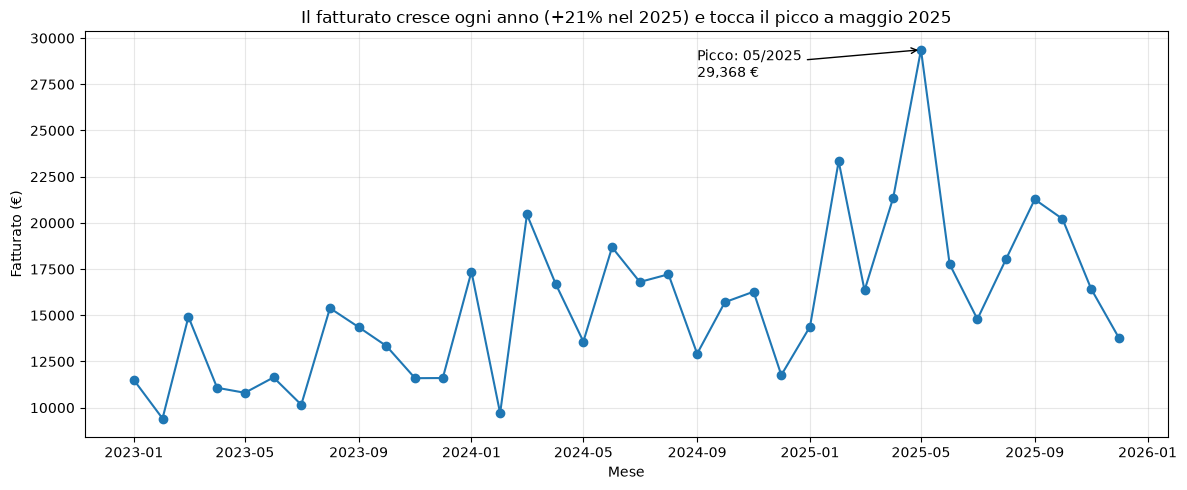

In [19]:
# Es 4 punto 1

# dalla serie mensile del Task 3c: indice (Year, Month) → colonne normali + data del mese
monthly_plot = monthly.reset_index()
monthly_plot["Period"] = pd.to_datetime(
    dict(year=monthly_plot["Year"], month=monthly_plot["Month"], day=1)
)

# mese di picco
peak = monthly_plot.loc[monthly_plot["Revenue"].idxmax()]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_plot["Period"], monthly_plot["Revenue"], marker="o")

# annotazione del mese di picco
ax.annotate(
    f"Picco: {peak['Period']:%m/%Y}\n{peak['Revenue']:,.0f} €",
    xy=(peak["Period"], peak["Revenue"]),
    xytext=(peak["Period"] - pd.DateOffset(months=8), peak["Revenue"] * 0.95),
    arrowprops=dict(arrowstyle="->"),
)

ax.set_title("Il fatturato cresce ogni anno (+21% nel 2025) e tocca il picco a maggio 2025")
ax.set_xlabel("Mese")
ax.set_ylabel("Fatturato (€)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Domanda di business:** come si è evoluto il fatturato mensile di ToysGroup tra il 2023 e il 2025, e quando ha raggiunto il suo massimo?


**Risposta:** il fatturato cresce ogni anno (da 145.805 € nel 2023 a 227.095 € nel 2025, +21% sull'anno precedente), pur con forti oscillazioni tra mesi consecutivi, e tocca il picco a maggio 2025 con 29.368 €.

Category
Outdoor             316.0
Giocattoli          236.0
Giochi da tavolo     89.5
Name: SalesAmount, dtype: float64


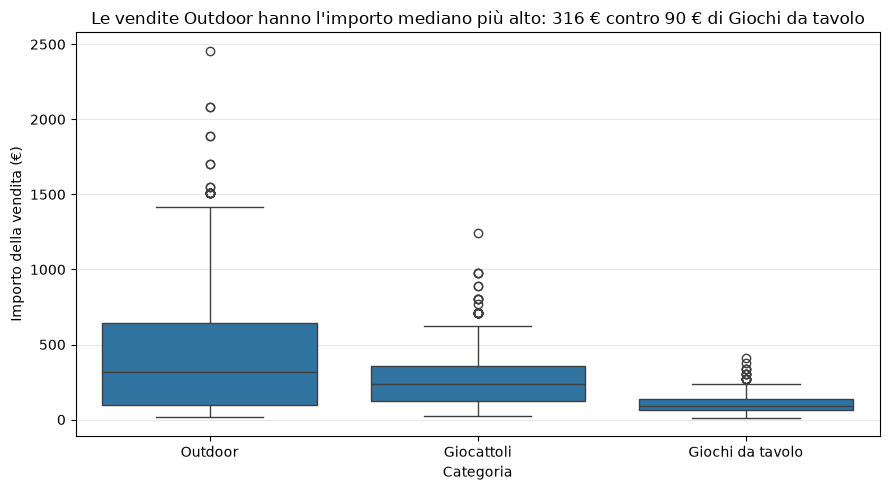

In [20]:
# Es 4 punto 2a

# mediana dell'importo per categoria, dalla più alta alla più bassa
medians = sales_full.groupby("Category")["SalesAmount"].median().sort_values(ascending=False)
top_cat, low_cat = medians.index[0], medians.index[-1]
print(medians)

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=sales_full,
    x="Category",
    y="SalesAmount",
    order=medians.index,
    ax=ax,
)

ax.set_title(
    f"Le vendite {top_cat} hanno l'importo mediano più alto: "
    f"{medians[top_cat]:,.0f} € contro {medians[low_cat]:,.0f} € di {low_cat}"
)
ax.set_xlabel("Categoria")
ax.set_ylabel("Importo della vendita (€)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Domanda di business:** l'importo delle singole vendite cambia in base alla categoria di prodotto?


**Risposta:** sì, la vendita tipica di Outdoor vale molto di più (mediana 316 €) rispetto a Giocattoli (236 €) e soprattutto a Giochi da tavolo (89,50 €), il che spiega perché Outdoor guida il fatturato pur con un numero di transazioni simile alle altre categorie.

                    Ordini12m  GiorniUltimoOrdine  ScontoMedio  Reclami  Churn
Ordini12m                1.00               -0.78         0.06     0.07  -0.35
GiorniUltimoOrdine      -0.78                1.00        -0.02    -0.10   0.43
ScontoMedio              0.06               -0.02         1.00    -0.01  -0.01
Reclami                  0.07               -0.10        -0.01     1.00   0.07
Churn                   -0.35                0.43        -0.01     0.07   1.00


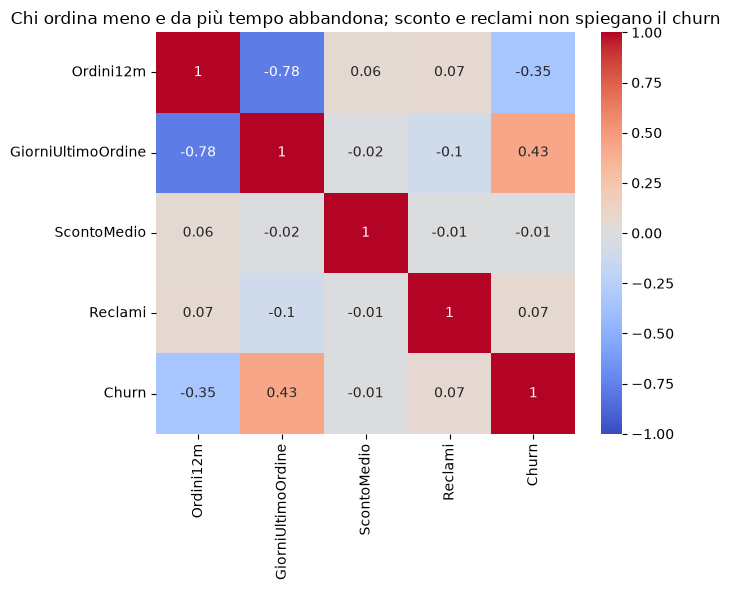

In [21]:
# Es 4 punto 2b

# variabili numeriche, esclusi gli identificativi
reseller_vars = ["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami", "Churn"]
corr = resellers_df[reseller_vars].corr().round(2)
print(corr)

# variabile più correlata con il churn (in valore assoluto)
churn_corr = corr["Churn"].drop("Churn")
top_var = churn_corr.abs().idxmax()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)

ax.set_title("Chi ordina meno e da più tempo abbandona; sconto e reclami non spiegano il churn")

plt.tight_layout()
plt.show()

In [22]:
# ulteriori verifiche

print("Massimo GiorniUltimoOrdine:", resellers_df["GiorniUltimoOrdine"].max())

display(pd.crosstab(resellers_df["GiorniUltimoOrdine"] > 180, resellers_df["Churn"]))

resellers_df.groupby("Churn")[reseller_vars[:-1]].mean().round(2)

Massimo GiorniUltimoOrdine: 180


Churn,0,1
GiorniUltimoOrdine,,
False,229,71


,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami
Churn,,,,
0,17.77,76.93,0.13,0.96
1,13.58,133.54,0.13,1.13


**Domanda di business:** quali caratteristiche dei rivenditori sono associate all'abbandono (churn)?


**Risposta:** il churn è associato ai giorni trascorsi dall'ultimo ordine (r = +0,43; in media 134 giorni per chi abbandona contro 77 per chi resta) e a un minor numero di ordini negli ultimi 12 mesi (r = −0,35; 13,6 contro 17,8), mentre lo sconto medio è identico nei due gruppi (13%) e i reclami non mostrano una relazione apprezzabile.

*Nota:* nessun rivenditore supera i 180 giorni dall'ultimo ordine, mentre 71 hanno Churn = 1: il churn è quindi un esito successivo alla rilevazione e non deriva per definizione da GiorniUltimoOrdine, che può essere usata come variabile predittiva. GiorniUltimoOrdine e Ordini12m sono però fortemente correlate tra loro (r = −0,78).

### Task 4 · Definizione richiesta
**Criterio di scelta del grafico**

Il tipo di grafico si sceglie in base alla domanda e al tipo di dato da rappresentare, non all'estetica.

| Obiettivo | Grafico | Perché | Nel Task 4 |
|---|---|---|---|
| **Andamento nel tempo** | linee | l'asse x è ordinato e continuo; la linea collega punti consecutivi e rende visibili tendenze, picchi e oscillazioni | fatturato mensile 2023–2025 |
| **Confronto tra categorie** | barre | la lunghezza delle barre si confronta a colpo d'occhio; l'ordine delle categorie non ha significato temporale | (fatturato per stato, grafico Plotly opzionale) |
| **Distribuzione** | boxplot (o istogramma) | mostra mediana, quartili, dispersione e valori anomali, cioè molto più di una sola media | SalesAmount per categoria |
| **Relazione tra variabili** | heatmap o scatter | la heatmap riassume le correlazioni di molte coppie di variabili in una sola figura; lo scatter (non usato qui) mostra nel dettaglio la relazione tra due variabili | heatmap delle correlazioni delle variabili di resellers |

Usare il grafico sbagliato può nascondere l'informazione: una linea tra categorie suggerirebbe un ordine o una continuità che non esistono, mentre delle barre con le sole medie nasconderebbero l'asimmetria degli importi che il boxplot rende evidente.

In tutti i grafici il titolo enuncia il risultato (es. "Il churn è legato soprattutto a GiorniUltimoOrdine"), così il lettore riceve subito il messaggio e il grafico serve a verificarlo.

In [23]:
# Es 4 punto 3

# fatturato, quantità e transazioni per stato
by_state = (
    sales_full
    .groupby("State")
    .agg(
        Revenue=("SalesAmount", "sum"),
        TotalQuantity=("Quantity", "sum"),
        Transactions=("SalesID", "count"),
        SalesRegion=("SalesRegion", "first"),
    )
    .sort_values("Revenue", ascending=False)
    .reset_index()
)

# scontrino medio per stato
by_state["AvgTicket"] = (by_state["Revenue"] / by_state["Transactions"]).round(2)

# dati per il titolo
top_state = by_state.loc[0, "State"]
top_share = by_state.loc[0, "Revenue"] / by_state["Revenue"].sum()

fig = px.bar(
    by_state,
    x="State",
    y="Revenue",
    color="SalesRegion",
    hover_data={
        "Revenue": ":,.2f",
        "TotalQuantity": ":,.0f",
        "Transactions": True,
        "SalesRegion": False,
        "AvgTicket": ":,.2f",
    },
    labels={
        "State": "Stato",
        "Revenue": "Fatturato (€)",
        "TotalQuantity": "Quantità totale",
        "Transactions": "Transazioni",
        "SalesRegion": "Regione di vendita",
        "AvgTicket": "Scontrino medio (€)",
    },
    title=(
        f"{top_state} è lo stato con il fatturato più alto: "
        f"{by_state.loc[0, 'Revenue']:,.0f} € ({top_share:.0%} del totale)"
    ),
)

fig.show()

by_state

,State,Revenue,TotalQuantity,Transactions,SalesRegion,AvgTicket
0,Austria,74426.4,1335.0,278,Centro Europa,267.72
1,Norvegia,71802.4,1240.0,244,Nord Europa,294.27
2,Germania,70867.6,1145.0,232,Centro Europa,305.46
3,Svezia,69482.2,1144.0,230,Nord Europa,302.10
4,Spagna,59227.8,1068.0,214,Sud Europa,276.77
5,Italia,56601.6,908.0,184,Sud Europa,307.62
6,Svizzera,55768.2,933.0,188,Centro Europa,296.64
7,Francia,52994.9,877.0,171,Sud Europa,309.91
8,Danimarca,48904.4,791.0,159,Nord Europa,307.57


**Domanda di business:** quali stati generano più fatturato, e il primato dipende dal numero di vendite o dal loro valore?


**Risposta:** l'Austria è prima con 74.426 € (13% del totale) grazie soprattutto al maggior numero di transazioni (278), pur avendo lo scontrino medio più basso tra tutti gli stati (circa 268 €), mentre la Danimarca è ultima con 48.905 €; i quattro stati in testa, divisi tra Centro e Nord Europa, sono molto vicini tra loro (tra 69.000 e 74.000 €).

*Nota:* il grafico è interattivo (Plotly): passando il mouse sulle barre compaiono fatturato, quantità totale e numero di transazioni (per vederlo però occorre aprire il file in Jupyter o VS Code).